# 9. Diseño de evaluación

El protocolo fija MASE como métrica primaria y MAE, RMSE y sMAPE como complementarias. La diferencia relativa de interés es δ = 3 %, con α = 0,05 y potencia objetivo 0,80. La unidad de evaluación es el origen diario que produce 24 etiquetas.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/processed/panel_horario.parquet').exists())
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
panel = pq.read_table(ROOT/'data/processed/panel_horario.parquet', filters=[('inicio','<',pd.Timestamp('2022-01-01',tz='America/Bogota'))]).to_pandas()
assert panel.index.max() < pd.Timestamp('2022-01-01',tz='America/Bogota')
assert panel.index.is_monotonic_increasing and panel.index.is_unique
y = panel['y_demanda_real_kwh']
gwh = y / 1e6
registro = json.loads((ROOT/'data/processed/feature_registry.json').read_text(encoding='utf-8'))


## Formulación y entradas

Para un origen diario $o$, la salida es $\mathbf{y}_o=(y_o,\ldots,y_{o+23})$. El pronóstico directo se expresa como

$$\widehat{\mathbf{y}}_o=f_\theta(\mathbf{X}_{o-168:o-1},\mathbf{K}_{o:o+23}),$$

donde $\mathbf{X}$ contiene observaciones pasadas alineadas por disponibilidad y $\mathbf{K}$ contiene calendario conocido. La configuración base utiliza demanda y calendario; clima, hidrología y titulares fundamentan extensiones posteriores.

La unidad de evaluación es el origen diario, con 24 errores relacionados. Las semillas describen variación del ajuste y no hacen independientes los errores de un mismo día.

La selección utiliza cuatro pliegues anuales: 2018, 2019, 2020 y 2021. El entrenamiento se amplía cronológicamente. El último 10 % de los orígenes anteriores a cada año se reserva para parada temprana. La prueba 2022–2025 queda fuera de este análisis. La escala semanal de MASE procede de entrenamiento; con demanda creciente no representa una escala intercambiable entre particiones.

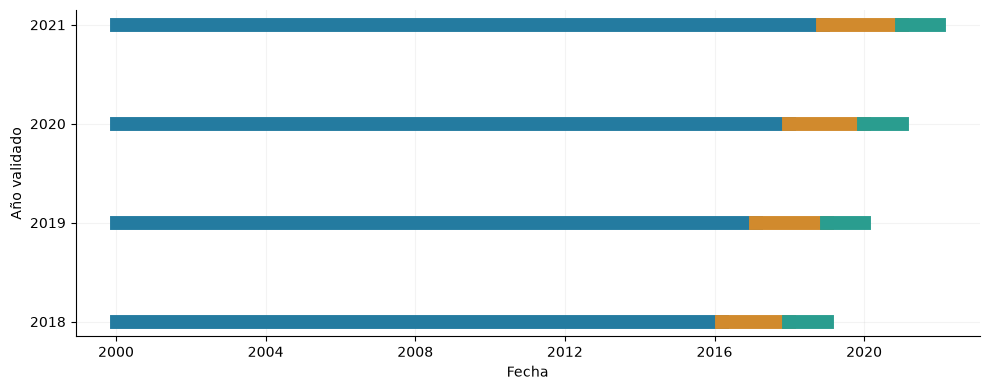

,año,entrenamiento,parada_interna,validacion
0,2018,5911,657,365
1,2019,6240,693,365
2,2020,6568,730,366
3,2021,6898,766,365


In [2]:
H=24; L=168; indice=panel.index; candidatos=np.arange(L,len(panel)-H+1); candidatos=candidatos[indice[candidatos].hour==0]; filas=[]; fig,ax=plt.subplots()
for fila,anio in enumerate([2018,2019,2020,2021]):
    inicio=pd.Timestamp(f'{anio}-01-01',tz='America/Bogota'); fin=pd.Timestamp(f'{anio+1}-01-01',tz='America/Bogota'); pre=candidatos[indice[candidatos]+pd.Timedelta(hours=H-1)<inicio]; n_es=max(1,round(.1*len(pre))); es=pre[-n_es:]; tr=pre[indice[pre]+pd.Timedelta(hours=H-1)<indice[es[0]]]; val=candidatos[(indice[candidatos]>=inicio)&(indice[candidatos]+pd.Timedelta(hours=H-1)<fin)]; assert indice[tr[-1]]+pd.Timedelta(hours=23)<indice[es[0]]; assert indice[es[-1]]+pd.Timedelta(hours=23)<indice[val[0]]
    filas.append({'año':anio,'entrenamiento':len(tr),'parada_interna':len(es),'validacion':len(val)})
    for posiciones,color in [(tr,'#247ba0'),(es,'#d18a2d'),(val,'#2a9d8f')]: ax.plot([indice[posiciones[0]],indice[posiciones[-1]]],[fila,fila],color=color,lw=10)
ax.set(yticks=range(4),yticklabels=range(2018,2022),xlabel='Fecha',ylabel='Año validado'); fig.tight_layout(); display(fig); plt.close(fig); display(pd.DataFrame(filas))

Cada bloque verde corresponde a un año posterior a la historia de ajuste; el tramo naranja reserva parada temprana dentro de esa historia. Los conteos verifican separación de etiquetas entre ajuste, parada y validación externa. El año 2020 conserva su propio pliegue, permitiendo identificar el comportamiento de ese régimen.

### Pipeline por origen

El panel aplica los rezagos de disponibilidad. Para un origen en la posición `p`, la historia contiene filas `p−168` a `p−1`, mientras el calendario del horizonte utiliza `p` a `p+23`. La demanda futura sólo se emplea como etiqueta. La media de demanda de la ventana es una escala conocida al origen.

In [3]:
p=int(candidatos[100]); historia=panel.iloc[p-L:p]; horizonte=panel.iloc[p:p+H]; X_pasado=historia[['x_demanda_real_kwh']].to_numpy(); calendario=[c for c in panel.columns if c.startswith('cal_') and pd.api.types.is_numeric_dtype(panel[c])]; K_futuro=horizonte[calendario].to_numpy(); Y=horizonte['y_demanda_real_kwh'].to_numpy(); nivel=float(X_pasado.mean()); X_nivel=X_pasado/nivel; Y_nivel=Y/nivel; assert historia.index.max()<horizonte.index.min(); assert nivel>0; display(pd.DataFrame([{'forma_historia':str(X_nivel.shape),'forma_calendario':str(K_futuro.shape),'forma_etiquetas':str(Y_nivel.shape),'nivel_kWh':nivel}]))
train=panel.loc[panel.index<'2018-01-01']; media_cal=train[calendario].mean(); escala_cal=train[calendario].std().replace(0,1); K_estandar=(horizonte[calendario]-media_cal)/escala_cal; escala_mase=float(train.y_demanda_real_kwh.diff(168).abs().dropna().mean()); display(pd.Series({'escala_MASE_semanal_kWh':escala_mase,'margen_relativo':.03,'alfa':.05,'potencia_objetivo':.8}))

,forma_historia,forma_calendario,forma_etiquetas,nivel_kWh
0,"(168, 1)","(24, 23)","(24,)",4.652567e+06


escala_MASE_semanal_kWh    215617.903616
margen_relativo                 0.030000
alfa                            0.050000
potencia_objetivo               0.800000
dtype: float64

**Decisión.** Separar ajuste, parada interna, validación externa y prueba.

**Impacto.** Homogeneiza la comparación y preserva el orden temporal.

**Riesgo.** La prueba retrospectiva y las versiones revisadas de las fuentes limitan la independencia histórica; la inferencia debe seguir su preregistro.

## Métricas y comparación

Para $N$ orígenes y $H=24$:

$$\operatorname{MAE}=\frac{1}{NH}\sum_o\sum_{h=0}^{H-1}|y_{o+h}-\widehat y_{o+h}|,$$

$$\operatorname{RMSE}=\sqrt{\frac{1}{NH}\sum_o\sum_{h=0}^{H-1}(y_{o+h}-\widehat y_{o+h})^2},\qquad
\operatorname{MASE}=\frac{\operatorname{MAE}}{q_{168}},$$

$$q_{168}=\frac{1}{T-168}\sum_{t=168}^{T-1}|y_t-y_{t-168}|.$$

La escala $q_{168}$ procede exclusivamente de entrenamiento 2000–2017. MASE es la métrica primaria; MAE se interpreta en kWh por intervalo y RMSE acentúa errores grandes. sMAPE promedia $200|y-\widehat y|/(|y|+|\widehat y|)$, con contribución cero cuando ambos son cero. Un MASE inferior a 1 compara con la escala histórica de entrenamiento; la comparación con el ingenuo en validación requiere calcular también su error sobre los mismos orígenes.

Persistencia y referencias diaria y semanal deben utilizar la misma disponibilidad que los modelos. El reporte desagrega por hora del horizonte, año y tipo de día, además de media, desviación e intervalos entre semillas. El margen relativo de interés es 3 %; α = 0,05 y potencia objetivo 0,80 son parámetros del diseño inferencial.

## Búsqueda y prevención de fuga

La ejecución v2 evaluó veinte configuraciones para MLP, CNN1D y ARX, y cinco para LSTM tras una adenda de costo computacional, con tres semillas y cuatro pliegues anuales. El presupuesto ejecutado es desigual. Cada ajuste tiene hasta 200 épocas; la parada temprana utiliza el tramo interno, paciencia entre 8, 15 y 25 y mejora mínima de $10^{-6}$. Se conserva el mejor estado según la pérdida interna y el año externo evalúa la configuración.

El pipeline ejecutado fija el estandarizador inicial con 2000–2017 y la escala MASE con ese mismo bloque; MLP y ARX añaden estandarización tabular ajustada con el tramo de optimización. La reserva interna del primer pliegue participa en el escalado inicial, limitación documentada en el capítulo de modelos. El nivel de cada ventana se calcula con sus 168 filas permitidas y se conserva para devolver las salidas a kWh. Las etiquetas completas de cada origen permanecen dentro de su partición.

El análisis secundario de los resultados guardados se documenta en el capítulo de modelos y su evaluación temporal. Una evaluación confirmatoria futura requiere un preregistro específico: hipótesis pareadas, tratamiento de dependencia temporal, corrección de multiplicidad y equivalencia. Se contempla remuestreo por bloques de orígenes; su longitud y las pruebas definitivas quedan pendientes de fijar. La ejecución v2 completó un piloto de cinco semillas y utilizó 195 semillas finales. El capítulo de modelos presenta el análisis secundario de esos resultados.

## Reproducibilidad

La reproducción conserva configuraciones, semillas, versión del protocolo, diccionario y separación temporal. Debe registrar versiones de dependencias, dispositivo CPU/GPU, duración y huellas de los archivos de entrada. Los resultados y predicciones se almacenan por versión del experimento, sin sobrescribir corridas.

## Unidad de evaluación, bloques y comparaciones

Para dos métodos $A$ y $B$, se define una pérdida por origen

$$\ell_{m,o}=\frac{1}{24q_{168}}\sum_{h=0}^{23}|y_{o+h}-\widehat y_{m,o+h}|,\qquad
d_o=\ell_{A,o}-\ell_{B,o}.$$

El apareamiento exige los mismos días y horizontes; las 24 horas no se tratan como réplicas independientes. El intervalo temporal se estimaría con bloques contiguos de días para conservar dependencia serial. La variación entre semillas se reportaría separadamente: no se concatenan como si multiplicaran el número de días observados.

El protocolo inferencial por completar debe fijar las comparaciones de las tres familias entre sí y frente a las referencias, corrección de Holm dentro de una familia definida de hipótesis, longitud del bloque, número de remuestreos y tratamiento de faltantes. Para cada comparación se reportarán diferencia, mejora relativa, intervalo y p ajustado. La equivalencia requiere un contraste específico con el margen del 3 %; no se concluye por ausencia de significación.

El dimensionamiento debe usar dispersión de diferencias pareadas y dependencia temporal. Los errores de validación que participaron en selección no se presentan como confirmación independiente; las pruebas definitivas y la potencia se fijarán antes de calcularlas.

## Implementación de remuestreo temporal

La función siguiente implementa índices de bootstrap circular por bloques. Su ejemplo utiliza un índice artificial, no errores ni resultados de modelos. El análisis secundario temporal utiliza 14 días como bloque principal y 7 y 28 como sensibilidad, conforme al plan registrado antes de cargar las predicciones.

In [4]:
def indices_bootstrap_bloques(n,longitud,rng):
    if not 1<=longitud<=n:
        raise ValueError('La longitud debe estar entre 1 y n.')
    comienzos=rng.integers(0,n,size=int(np.ceil(n/longitud)))
    return ((comienzos[:,None]+np.arange(longitud))%n).ravel()[:n]

rng=np.random.default_rng(11037)
ejemplo=indices_bootstrap_bloques(60,14,rng)
assert ejemplo.shape==(60,) and ejemplo.min()>=0 and ejemplo.max()<60


En una evaluación futura, los mismos índices se aplicarían conjuntamente a las pérdidas de ambos métodos. El remuestreo debe respetar los bloques de evaluación y cualquier cambio del procedimiento de reajuste; no debe cruzarlos indiscriminadamente.